# Telecom Customer Churn — A Classification Study

**Author:** Leelavathi.R  ·  **Course:** Machine Learning Lab

I want to predict whether a telecom customer is about to **churn** (leave) or
**stay**. Since the answer is one of two labels, this is a **binary
classification** problem. I train five classifiers on the same data and compare
them using six metrics.

I kept the explanations beginner-friendly because I am still learning ML.


## Step 0 — Libraries and settings

A single configuration block holds every "knob" (seed, split size, column names)
so the experiment is easy to tweak and fully repeatable.


In [1]:
import warnings, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             roc_curve, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="ticks", palette="Set2")

SEED = 2026          # my fixed random seed -> identical results every run
HOLDOUT = 0.20       # fraction kept aside for final testing
TARGET = "Churn"     # the column we predict
CV_FOLDS = 5

In [2]:
# If opened from the model/ folder, hop up to the project root so the
# relative paths (data/, outputs/, model/) resolve correctly.
if os.path.basename(os.getcwd()) == "model":
    os.chdir("..")
os.makedirs("outputs", exist_ok=True)
print("Working directory:", Path.cwd().name)

Working directory: customer-churn-ml-classification


## Step 1 — Meet the data

Telco Customer Churn: 7,043 customers, 21 columns. First a quick profile.


In [3]:
churn_df = pd.read_csv("data/telco_customers.csv")
print("Shape:", churn_df.shape)
churn_df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Which columns are text (categorical) vs numeric?
text_cols = churn_df.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = churn_df.select_dtypes(include=["number"]).columns.tolist()
print("Text columns:", text_cols)
print("Numeric columns:", num_cols)

Text columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']
Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges']


### The label and its (im)balance

About **73% stay** and **27% churn** — imbalanced. A model that always guesses
"stay" would score ~73% accuracy yet be useless, so I rely on **AUC, F1 and MCC**,
split with **stratification**, and **re-weight the classes** inside the models
that support it.


Churn
No     5174
Yes    1869
Name: count, dtype: int64 

Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64

Imbalance ratio = 2.77 : 1


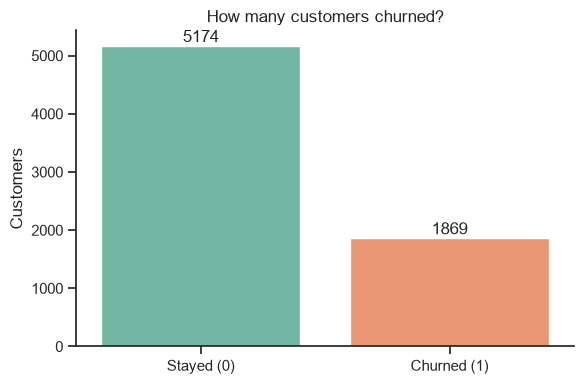

In [5]:
print(churn_df[TARGET].value_counts(), "\n")
print(churn_df[TARGET].value_counts(normalize=True).round(4))
ratio = churn_df[TARGET].value_counts().max() / churn_df[TARGET].value_counts().min()
print(f"\nImbalance ratio = {ratio:.2f} : 1")

plt.figure(figsize=(6,4))
tmp = churn_df.assign(**{TARGET: churn_df[TARGET].map({"Yes":1,"No":0})})
ax = sns.countplot(x=TARGET, data=tmp, hue=TARGET, legend=False)
ax.set_xticks([0,1]); ax.set_xticklabels(["Stayed (0)","Churned (1)"])
ax.set_title("How many customers churned?"); ax.set_xlabel(""); ax.set_ylabel("Customers")
for b in ax.patches:
    ax.annotate(f"{int(b.get_height())}", (b.get_x()+b.get_width()/2, b.get_height()),
                ha="center", va="bottom")
sns.despine(); plt.tight_layout(); plt.show()

### Hidden missing values

pandas reports 0 nulls, but `TotalCharges` is text with 11 blank entries — missing
values in disguise that we must fix.


In [6]:
print("Explicit NaN:", churn_df.isnull().sum().sum())
print("Blank TotalCharges:", (churn_df["TotalCharges"].astype(str).str.strip()=="").sum())
print("Duplicate rows:", churn_df.duplicated().sum())

Explicit NaN: 0
Blank TotalCharges: 11
Duplicate rows: 0


## Step 2 — Clean the data (deterministic steps only)

These steps don't *learn* anything from the data, so they're safe before the split:
drop the ID, fix `TotalCharges`, drop duplicates, encode the label to 1/0.
Statistics-based steps (imputing, scaling, encoding categories) wait for the
Pipeline so they're fitted on **training data only** → no data leakage.


In [7]:
data = churn_df.drop(columns=["customerID"])
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
print("TotalCharges NaN after fix:", data["TotalCharges"].isnull().sum())

before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print("Duplicates dropped:", before - len(data))

data[TARGET] = data[TARGET].map({"Yes":1, "No":0})   # churn = 1 (positive class)
data.head()

TotalCharges NaN after fix: 11
Duplicates dropped: 22


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


### Split 80 / 20 (stratified) and save the hold-out set

In [8]:
feature_matrix = data.drop(columns=[TARGET])
churn_label = data[TARGET]

X_fit, X_eval, y_fit, y_eval = train_test_split(
    feature_matrix, churn_label, test_size=HOLDOUT, stratify=churn_label, random_state=SEED)

print("Learn:", len(X_fit), "| Test:", len(X_eval))
print(f"Churn share -> learn {y_fit.mean():.3f}, test {y_eval.mean():.3f}")

holdout = X_eval.copy(); holdout[TARGET] = y_eval.values
holdout.to_csv("test_data.csv", index=False)

Learn: 5616 | Test: 1405
Churn share -> learn 0.264, test 0.265


### Build the transformer

Numeric → median-impute then standardise. Categorical → most-frequent-impute then
one-hot encode. It is fitted later, inside each model's Pipeline, on training rows only.


In [9]:
numeric_cols = feature_matrix.select_dtypes(include=["number"]).columns.tolist()
text_cols = [c for c in feature_matrix.columns if c not in numeric_cols]
print("Numeric:", numeric_cols); print("Categorical:", text_cols)

numeric_branch = Pipeline([("fill_gaps", SimpleImputer(strategy="median")),
                           ("standardise", StandardScaler())])
text_branch = Pipeline([("fill_gaps", SimpleImputer(strategy="most_frequent")),
                        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
transformer = ColumnTransformer([("numeric", numeric_branch, numeric_cols),
                                 ("text", text_branch, text_cols)])
transformer

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('text', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## Step 3 — Five classifiers, with my own settings

Where a model supports `class_weight`, I set it to **balanced** so the rare
"churn" class is taken seriously. kNN and Gaussian Naive Bayes have no such option,
so for them I rely on the stratified split and the robust metrics.

Each model is wrapped with the **same transformer** in a Pipeline. A quick
**5-fold cross-validation** on the training data checks that the AUC is stable
before I ever touch the hold-out set.


In [10]:
zoo = {
    "Logistic Regression": ("logreg", LogisticRegression(C=0.3, class_weight="balanced",
                             solver="liblinear", max_iter=500, random_state=SEED)),
    "Decision Tree": ("dtree", DecisionTreeClassifier(criterion="entropy", max_depth=7,
                       min_samples_leaf=25, class_weight="balanced", random_state=SEED)),
    "kNN": ("knn", KNeighborsClassifier(n_neighbors=21, weights="distance", p=1)),
    "Naive Bayes": ("gnb", GaussianNB(var_smoothing=1e-8)),
    "Random Forest (Ensemble)": ("rforest", RandomForestClassifier(n_estimators=250,
                                  max_depth=10, min_samples_leaf=5, max_features="sqrt",
                                  class_weight="balanced_subsample", random_state=SEED)),
}

Path("model").mkdir(exist_ok=True)
kfold = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
score_rows, prob_lookup, cm_lookup = [], {}, {}

for name, (tag, estimator) in zoo.items():
    pipe = Pipeline([("prep", transformer), ("clf", estimator)])

    cv_auc = cross_val_score(pipe, X_fit, y_fit, cv=kfold, scoring="roc_auc")
    pipe.fit(X_fit, y_fit)

    pred = pipe.predict(X_eval)
    prob = pipe.predict_proba(X_eval)[:, 1]
    score_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "AUC": roc_auc_score(y_eval, prob),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_eval, pred),
    })
    prob_lookup[name] = prob
    cm_lookup[name] = confusion_matrix(y_eval, pred)
    joblib.dump(pipe, f"model/clf_{tag}.joblib")
    print(f"{name:<26} CV-AUC={cv_auc.mean():.4f} (+/-{cv_auc.std():.4f})")

print("\nAll five models trained and saved.")

Logistic Regression        CV-AUC=0.8457 (+/-0.0166)


Decision Tree              CV-AUC=0.8236 (+/-0.0138)


kNN                        CV-AUC=0.8017 (+/-0.0111)
Naive Bayes                CV-AUC=0.8190 (+/-0.0162)


Random Forest (Ensemble)   CV-AUC=0.8464 (+/-0.0135)

All five models trained and saved.


### The leaderboard (six metrics on the hold-out set)

- **Accuracy** — overall fraction correct
- **AUC** — ranking quality, robust to imbalance
- **Precision** — of predicted churners, how many truly churned
- **Recall** — of real churners, how many we caught
- **F1** — balance of precision and recall
- **MCC** — balanced correlation (−1..+1), honest under imbalance


In [11]:
leaderboard = pd.DataFrame(score_rows)
cols = ["Accuracy","AUC","Precision","Recall","F1","MCC"]
leaderboard[cols] = leaderboard[cols].round(4)
leaderboard.to_csv("outputs/metrics_comparison.csv", index=False)
leaderboard

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.7488,0.8407,0.5167,0.7903,0.6249,0.4711
1,Decision Tree,0.7395,0.8189,0.5051,0.7984,0.6188,0.4621
2,kNN,0.7694,0.7974,0.5736,0.5027,0.5358,0.3848
3,Naive Bayes,0.6996,0.8165,0.4626,0.8306,0.5942,0.4268
4,Random Forest (Ensemble),0.7758,0.8445,0.5580,0.7366,0.6350,0.4872


### Visualise all metrics

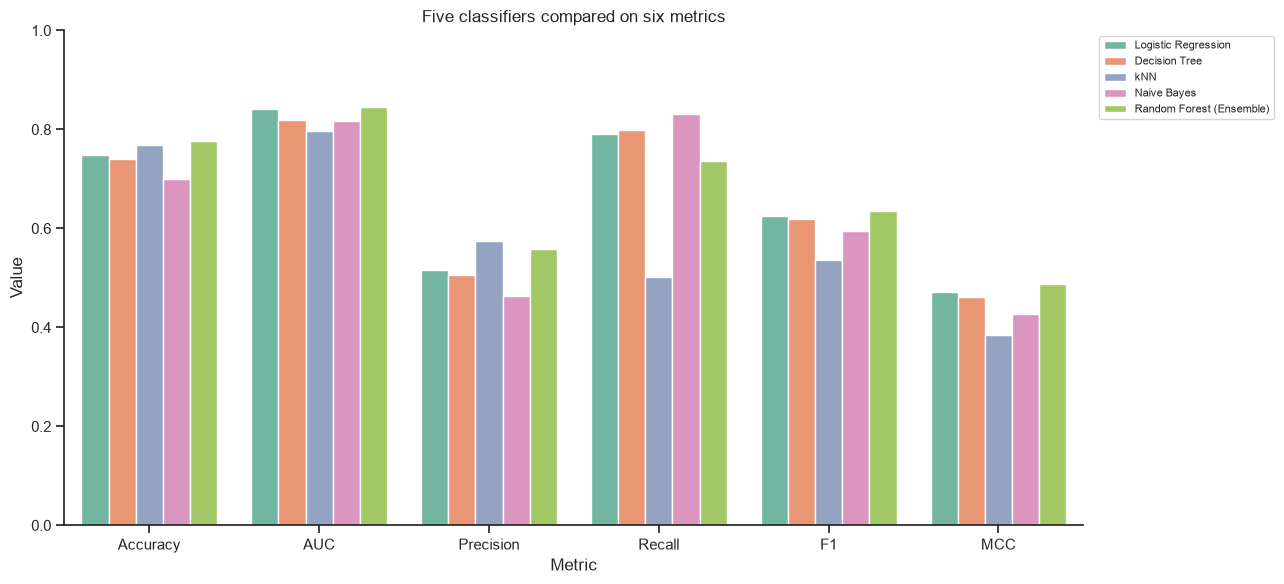

In [12]:
long = leaderboard.melt(id_vars="Model", value_vars=cols, var_name="Metric", value_name="Value")
plt.figure(figsize=(13,6))
ax = sns.barplot(data=long, x="Metric", y="Value", hue="Model")
ax.set_title("Five classifiers compared on six metrics"); ax.set_ylim(0,1)
ax.legend(bbox_to_anchor=(1.01,1), loc="upper left", fontsize=8)
sns.despine(); plt.tight_layout(); plt.show()

### ROC curves

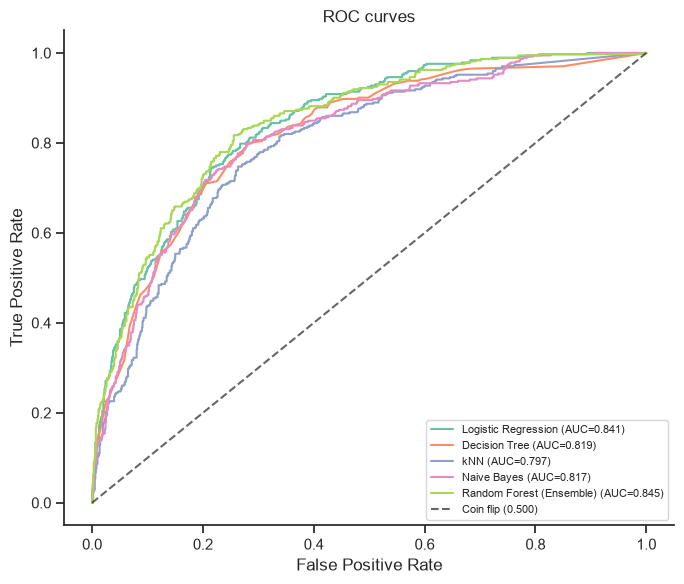

In [13]:
plt.figure(figsize=(7,6))
for name, prob in prob_lookup.items():
    fpr, tpr, _ = roc_curve(y_eval, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_eval, prob):.3f})")
plt.plot([0,1],[0,1],"k--", alpha=0.6, label="Coin flip (0.500)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC curves")
plt.legend(loc="lower right", fontsize=8); sns.despine(); plt.tight_layout(); plt.show()

### Confusion matrices

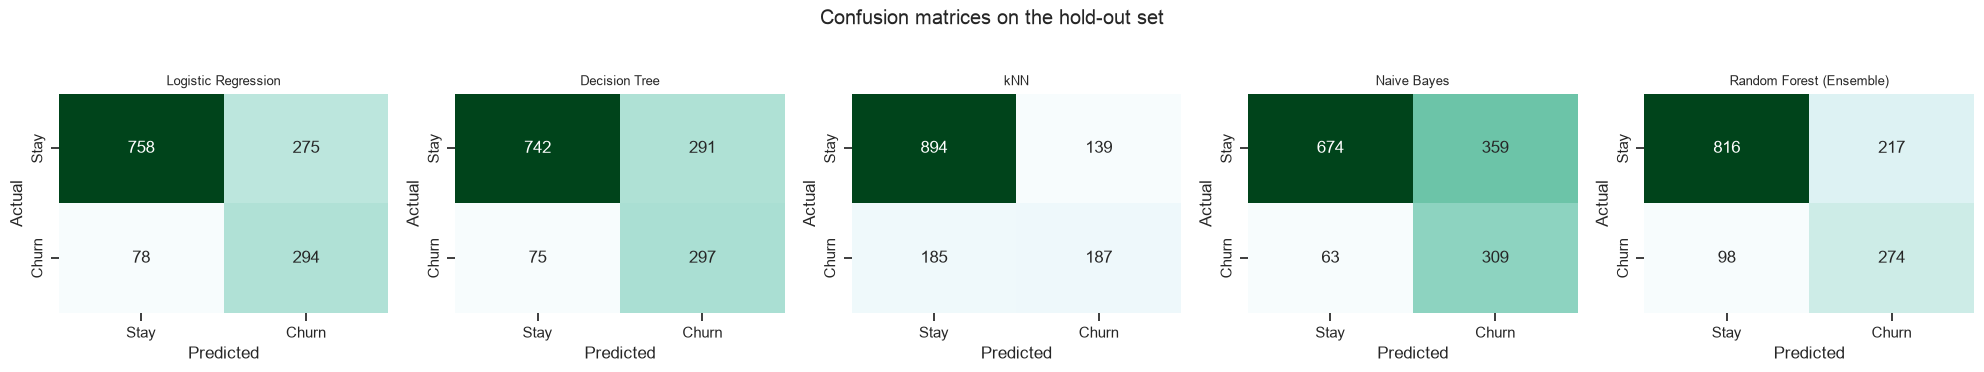

In [14]:
fig, axes = plt.subplots(1, len(cm_lookup), figsize=(4*len(cm_lookup), 3.6))
for ax, (name, cm) in zip(axes, cm_lookup.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="BuGn", cbar=False, ax=ax,
                xticklabels=["Stay","Churn"], yticklabels=["Stay","Churn"])
    ax.set_title(name, fontsize=9); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion matrices on the hold-out set", y=1.03)
plt.tight_layout(); plt.show()

### Pick the winner

In [15]:
champion = leaderboard.loc[leaderboard["AUC"].idxmax(), "Model"]
print("Best AUC on this dataset ->", champion)

Best AUC on this dataset -> Random Forest (Ensemble)


## Conclusion

Because I re-weighted the classes, every model now leans towards **catching
churners** (higher recall) at some cost to precision. The **Random Forest** gives
the best AUC, F1 and MCC overall, so it is my chosen model. See **README.md** for
the full written observations on each model.

> Run everything with **Kernel → Restart & Run All**, then capture the BITS
> Virtual Lab screenshot.
